# 02 — Harmonisation des datasets CIC-IDS2017 et UNSW-NB15

## Objectif
Construire deux échantillons reproductibles de 100 000 observations, harmoniser cinq variables communes, créer une cible binaire, contrôler la qualité des données et analyser les doublons afin de préparer les expériences de généralisation.

**Règles méthodologiques**
- Les fichiers bruts ne sont jamais modifiés.
- Les données sont lues par blocs (`chunksize=100_000`).
- L'échantillonnage conserve l'algorithme global à clés aléatoires, avec `random_state=42`.
- La durée CIC (`Flow Duration`) est convertie une seule fois de microsecondes en secondes.
- Les labels restent séparés des variables explicatives.
- Les durées CIC négatives sont auditées dans les données brutes harmonisées, puis corrigées uniquement dans une copie de travail.
- Les fichiers de séparation `.npz` existants ne sont pas écrasés par ce notebook.

## 1. Imports et chemins du projet

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

# Le notebook est prévu dans <racine_projet>/notebooks/.
CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR / "data" / "raw").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "raw").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Racine du projet introuvable. Ouvrir Jupyter depuis le dossier du projet "
        "ou placer ce notebook dans le dossier notebooks/."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results" / "tables"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_SIZE = 100_000
CHUNK_SIZE = 100_000
RANDOM_STATE = 42

FEATURE_COLUMNS = [
    "flow_duration_s",
    "fwd_packets",
    "bwd_packets",
    "fwd_bytes",
    "bwd_bytes",
]

print("Racine du projet :", PROJECT_ROOT)
print("Données brutes :", RAW_DIR)
print("Résultats :", RESULTS_DIR)
print("Taille échantillon :", SAMPLE_SIZE)
print("Chunk size :", CHUNK_SIZE)
assert RAW_DIR.exists(), f"Dossier introuvable : {RAW_DIR}"

Racine du projet : D:\Master-SDIA\CYB-1-IDS-Generalization
Données brutes : D:\Master-SDIA\CYB-1-IDS-Generalization\data\raw
Résultats : D:\Master-SDIA\CYB-1-IDS-Generalization\results\tables
Taille échantillon : 100000
Chunk size : 100000


## 2. Localisation et vérification des fichiers sources

In [2]:
cic_files = sorted(
    f for f in RAW_DIR.rglob("*.csv")
    if "CIC-IDS2017" in str(f)
)

unsw_expected_names = {
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv",
}
unsw_files = sorted(
    f for f in RAW_DIR.rglob("UNSW-NB15_*.csv")
    if f.name in unsw_expected_names
)

feature_files = list(RAW_DIR.rglob("NUSW-NB15_features.csv"))

print("Fichiers CIC trouvés :", len(cic_files))
for f in cic_files:
    print(" -", f.relative_to(RAW_DIR))

print("\nFichiers UNSW trouvés :", len(unsw_files))
for f in unsw_files:
    print(" -", f.relative_to(RAW_DIR))

print("\nFichiers descriptif UNSW :", len(feature_files))

assert len(cic_files) == 8, f"8 fichiers CIC attendus, {len(cic_files)} trouvés."
assert len(unsw_files) == 4, f"4 fichiers UNSW attendus, {len(unsw_files)} trouvés."
assert len(feature_files) == 1, "Le fichier NUSW-NB15_features.csv doit être unique."

FEATURES_FILE = feature_files[0]

Fichiers CIC trouvés : 8
 - CIC-IDS2017\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - CIC-IDS2017\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - CIC-IDS2017\Friday-WorkingHours-Morning.pcap_ISCX.csv
 - CIC-IDS2017\Monday-WorkingHours.pcap_ISCX.csv
 - CIC-IDS2017\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - CIC-IDS2017\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - CIC-IDS2017\Tuesday-WorkingHours.pcap_ISCX.csv
 - CIC-IDS2017\Wednesday-workingHours.pcap_ISCX.csv

Fichiers UNSW trouvés : 4
 - UNSW-NB15\UNSW-NB15_1.csv
 - UNSW-NB15\UNSW-NB15_2.csv
 - UNSW-NB15\UNSW-NB15_3.csv
 - UNSW-NB15\UNSW-NB15_4.csv

Fichiers descriptif UNSW : 1


## 3. Définition du schéma commun et des labels

Les cinq variables sont harmonisées selon les correspondances validées lors de l'audit. Les colonnes de ports et `attack_cat` ne sont pas utilisées dans ce schéma initial.

In [3]:
UNSW_USECOLS = [6, 7, 8, 16, 17, 48]

# Les positions sont celles du fichier UNSW-NB15 sans en-tête.
# Pandas restitue les colonnes dans l'ordre physique du fichier.
UNSW_POSITION_TO_NAME = {
    6: "flow_duration_s",
    7: "fwd_bytes",
    8: "bwd_bytes",
    16: "fwd_packets",
    17: "bwd_packets",
    48: "Label",
}

CIC_USECOLS = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Label",
]

CIC_RENAME = {
    "Flow Duration": "flow_duration_s",
    "Total Fwd Packets": "fwd_packets",
    "Total Backward Packets": "bwd_packets",
    "Total Length of Fwd Packets": "fwd_bytes",
    "Total Length of Bwd Packets": "bwd_bytes",
    "Label": "Label",
}

print("Variables explicatives :", FEATURE_COLUMNS)
print("Cible : target (0 = normal, 1 = attaque)")

Variables explicatives : ['flow_duration_s', 'fwd_packets', 'bwd_packets', 'fwd_bytes', 'bwd_bytes']
Cible : target (0 = normal, 1 = attaque)


## 4. Échantillonnage aléatoire global reproductible

La fonction ci-dessous conserve les observations possédant les `SAMPLE_SIZE` plus petites clés aléatoires. Le générateur est réinitialisé séparément pour chaque dataset afin de préserver le protocole d'échantillonnage appliqué dans le pipeline précédent.

In [4]:
def global_random_sample(chunks, sample_size, rng):
    reservoir = pd.DataFrame()
    total_rows = 0

    for chunk in chunks:
        if chunk.empty:
            continue

        total_rows += len(chunk)
        chunk = chunk.copy()
        chunk["_random_key"] = rng.random(len(chunk))

        reservoir = pd.concat([reservoir, chunk], ignore_index=True)

        if len(reservoir) > sample_size:
            reservoir = (
                reservoir.nsmallest(sample_size, "_random_key")
                .reset_index(drop=True)
            )

    if not reservoir.empty:
        reservoir = reservoir.drop(columns="_random_key")

    return reservoir.reset_index(drop=True), total_rows

## 5. Lecture par blocs des fichiers UNSW-NB15

In [5]:
def read_unsw_labeled_chunks(files):
    for file in files:
        print(f"Lecture UNSW : {file.name}")
        reader = pd.read_csv(
            file,
            header=None,
            usecols=UNSW_USECOLS,
            chunksize=CHUNK_SIZE,
            low_memory=False,
        )
        for chunk in reader:
            # Renommage par position ; les positions sélectionnées sont conservées.
            chunk = chunk.rename(columns=UNSW_POSITION_TO_NAME)
            yield chunk

## 6. Lecture par blocs des fichiers CIC-IDS2017

In [6]:
def read_cic_labeled_chunks(files):
    for file in files:
        print(f"Lecture CIC : {file.name}")
        reader = pd.read_csv(
            file,
            chunksize=CHUNK_SIZE,
            low_memory=False,
            usecols=lambda col: col.strip() in CIC_USECOLS,
        )
        for chunk in reader:
            chunk.columns = chunk.columns.str.strip()
            chunk = chunk.rename(columns=CIC_RENAME)
            yield chunk

## 7. Construction des échantillons avec labels

**Point de contrôle important :** la conversion de la durée CIC est faite ici une seule fois. Ne pas réexécuter une cellule de conversion indépendante par la suite.

In [7]:
unsw_labeled, unsw_total_rows = global_random_sample(
    read_unsw_labeled_chunks(unsw_files),
    SAMPLE_SIZE,
    np.random.default_rng(RANDOM_STATE),
)

cic_labeled, cic_total_rows = global_random_sample(
    read_cic_labeled_chunks(cic_files),
    SAMPLE_SIZE,
    np.random.default_rng(RANDOM_STATE),
)

# Conversion unique : CIC Flow Duration est exprimée en microsecondes.
cic_labeled["flow_duration_s"] = (
    pd.to_numeric(cic_labeled["flow_duration_s"], errors="coerce") / 1_000_000
)

# Conversion numérique des cinq variables explicatives.
for df in (unsw_labeled, cic_labeled):
    for col in FEATURE_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Labels binaires.
unsw_labeled["target"] = pd.to_numeric(
    unsw_labeled["Label"], errors="coerce"
)
cic_labeled["target"] = (
    cic_labeled["Label"].astype(str).str.strip().str.upper().ne("BENIGN").astype(int)
)

# Les labels UNSW doivent être numériques et binaires.
unsw_labeled = unsw_labeled.dropna(subset=["target"]).copy()
unsw_labeled["target"] = unsw_labeled["target"].astype(int)
cic_labeled["target"] = cic_labeled["target"].astype(int)

print("UNSW lignes parcourues :", unsw_total_rows)
print("UNSW échantillon :", unsw_labeled.shape)
print("CIC lignes parcourues :", cic_total_rows)
print("CIC échantillon :", cic_labeled.shape)

print("\nRépartition UNSW :")
display(unsw_labeled["target"].value_counts().sort_index().rename(index={0: "Normal", 1: "Attaque"}))
print("\nRépartition CIC :")
display(cic_labeled["target"].value_counts().sort_index().rename(index={0: "Normal", 1: "Attaque"}))

Lecture UNSW : UNSW-NB15_1.csv
Lecture UNSW : UNSW-NB15_2.csv
Lecture UNSW : UNSW-NB15_3.csv
Lecture UNSW : UNSW-NB15_4.csv
Lecture CIC : Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Lecture CIC : Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Lecture CIC : Friday-WorkingHours-Morning.pcap_ISCX.csv
Lecture CIC : Monday-WorkingHours.pcap_ISCX.csv
Lecture CIC : Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Lecture CIC : Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Lecture CIC : Tuesday-WorkingHours.pcap_ISCX.csv
Lecture CIC : Wednesday-workingHours.pcap_ISCX.csv
UNSW lignes parcourues : 2540047
UNSW échantillon : (100000, 7)
CIC lignes parcourues : 2830743
CIC échantillon : (100000, 7)

Répartition UNSW :


target
Normal     87423
Attaque    12577
Name: count, dtype: int64


Répartition CIC :


target
Normal     80212
Attaque    19788
Name: count, dtype: int64

## 8. Vérifications structurelles

In [8]:
expected_columns = FEATURE_COLUMNS + ["Label", "target"]

for name, df in (("UNSW-NB15", unsw_labeled), ("CIC-IDS2017", cic_labeled)):
    missing_columns = [c for c in expected_columns if c not in df.columns]
    assert not missing_columns, f"{name} : colonnes manquantes {missing_columns}"
    assert len(df) == min(SAMPLE_SIZE, unsw_total_rows if name == "UNSW-NB15" else cic_total_rows)
    assert df["target"].notna().all(), f"{name} : target contient des valeurs manquantes"
    assert set(df["target"].unique()).issubset({0, 1}), f"{name} : target non binaire"
    assert df[FEATURE_COLUMNS].dtypes.apply(lambda x: pd.api.types.is_numeric_dtype(x)).all()

print("Vérifications structurelles réussies.")
print("UNSW :", unsw_labeled[FEATURE_COLUMNS + ["target"]].shape)
print("CIC :", cic_labeled[FEATURE_COLUMNS + ["target"]].shape)

Vérifications structurelles réussies.
UNSW : (100000, 6)
CIC : (100000, 6)


## 9. Audit de qualité des variables

Les valeurs manquantes, infinies, négatives et nulles sont comptabilisées avant toute correction.

In [9]:
def audit_sample(df, dataset_name):
    rows = []
    for col in FEATURE_COLUMNS:
        values = pd.to_numeric(df[col], errors="coerce")
        array = values.to_numpy(dtype=float)
        rows.append({
            "dataset": dataset_name,
            "feature": col,
            "missing": int(values.isna().sum()),
            "infinite": int(np.isinf(array).sum()),
            "negative": int((values < 0).sum()),
            "zeros": int((values == 0).sum()),
            "min": values.min(),
            "median": values.median(),
            "max": values.max(),
        })
    return pd.DataFrame(rows)

quality_report = pd.concat([
    audit_sample(unsw_labeled, "UNSW-NB15"),
    audit_sample(cic_labeled, "CIC-IDS2017"),
], ignore_index=True)

display(quality_report)
quality_report.to_csv(RESULTS_DIR / "harmonized_samples_quality_v2.csv", index=False, encoding="utf-8-sig")
print("Audit qualité sauvegardé.")

,dataset,feature,missing,infinite,negative,zeros,min,median,max
0,UNSW-NB15,flow_duration_s,0,0,0,298,0.000000,0.015872,5.999994e+01
1,UNSW-NB15,fwd_packets,0,0,0,1,0.000000,12.000000,5.370000e+03
2,UNSW-NB15,bwd_packets,0,0,0,19557,0.000000,12.000000,4.455000e+03
3,UNSW-NB15,fwd_bytes,0,0,0,1,0.000000,1470.000000,7.162482e+06
4,UNSW-NB15,bwd_bytes,0,0,0,19557,0.000000,1832.000000,6.040578e+06
5,CIC-IDS2017,flow_duration_s,0,0,5,104,-0.000002,0.031315,1.200000e+02
6,CIC-IDS2017,fwd_packets,0,0,0,0,1.000000,2.000000,1.982230e+05
7,CIC-IDS2017,bwd_packets,0,0,0,15930,0.000000,2.000000,2.701650e+05
8,CIC-IDS2017,fwd_bytes,0,0,0,15876,0.000000,62.000000,1.173813e+06
9,CIC-IDS2017,bwd_bytes,0,0,0,24910,0.000000,122.000000,5.810000e+08


Audit qualité sauvegardé.


## 10. Analyse des durées négatives et copie de travail

Les durées négatives CIC observées sont conservées dans `cic_labeled` pour la traçabilité. Le clipping à zéro est appliqué uniquement à `cic_model_sample`, utilisé ensuite pour les expériences.

In [10]:
negative_duration_count = int((cic_labeled["flow_duration_s"] < 0).sum())
print("Durées CIC négatives avant correction :", negative_duration_count)
print("Durées UNSW négatives :", int((unsw_labeled["flow_duration_s"] < 0).sum()))

unsw_model_sample = unsw_labeled.copy()
cic_model_sample = cic_labeled.copy()

cic_model_sample["flow_duration_s"] = cic_model_sample["flow_duration_s"].clip(lower=0)

print("Durées CIC négatives après correction dans la copie :", int((cic_model_sample["flow_duration_s"] < 0).sum()))
print("Durées CIC négatives dans l'échantillon source :", int((cic_labeled["flow_duration_s"] < 0).sum()))

assert (cic_model_sample["flow_duration_s"] >= 0).all()

Durées CIC négatives avant correction : 5
Durées UNSW négatives : 0
Durées CIC négatives après correction dans la copie : 0
Durées CIC négatives dans l'échantillon source : 5


## 11. Préparation des matrices X et y

In [11]:
X_unsw = unsw_model_sample[FEATURE_COLUMNS].copy()
y_unsw = unsw_model_sample["target"].copy()

X_cic = cic_model_sample[FEATURE_COLUMNS].copy()
y_cic = cic_model_sample["target"].copy()

for name, X, y in (("UNSW-NB15", X_unsw, y_unsw), ("CIC-IDS2017", X_cic, y_cic)):
    assert list(X.columns) == FEATURE_COLUMNS
    assert len(X) == len(y)
    assert X.isna().sum().sum() == 0, f"{name} : valeurs manquantes"
    assert np.isfinite(X.to_numpy(dtype=float)).all(), f"{name} : valeurs infinies"
    assert set(y.unique()) == {0, 1}, f"{name} : classes attendues 0 et 1"

print("UNSW X :", X_unsw.shape, "| y :", y_unsw.shape)
print("CIC X :", X_cic.shape, "| y :", y_cic.shape)
print("Matrices prêtes pour les analyses suivantes.")

UNSW X : (100000, 5) | y : (100000,)
CIC X : (100000, 5) | y : (100000,)
Matrices prêtes pour les analyses suivantes.


## 12. Statistiques descriptives et comparaison des distributions

In [12]:
unsw_stats = X_unsw.describe().T
cic_stats = X_cic.describe().T

display(pd.concat({"UNSW-NB15": unsw_stats, "CIC-IDS2017": cic_stats}, axis=1))

distribution_comparison = pd.DataFrame({
    "UNSW_median": X_unsw.median(),
    "CIC_median": X_cic.median(),
    "UNSW_q25": X_unsw.quantile(0.25),
    "CIC_q25": X_cic.quantile(0.25),
    "UNSW_q75": X_unsw.quantile(0.75),
    "CIC_q75": X_cic.quantile(0.75),
})
display(distribution_comparison)

unsw_stats.to_csv(RESULTS_DIR / "unsw_harmonized_sample_statistics_v2.csv", encoding="utf-8-sig")
cic_stats.to_csv(RESULTS_DIR / "cic_harmonized_sample_statistics_v2.csv", encoding="utf-8-sig")
distribution_comparison.to_csv(RESULTS_DIR / "global_distribution_comparison_v2.csv", encoding="utf-8-sig")

UNSW-NB15                                                                                        CIC-IDS2017  \
                    count          mean            std  min         25%          50%           75%           max       count   
flow_duration_s  100000.0      0.631443       3.453787  0.0    0.001038     0.015872      0.207732  5.999994e+01    100000.0   
fwd_packets      100000.0     33.656080      71.032595  0.0    2.000000    12.000000     44.000000  5.370000e+03    100000.0   
bwd_packets      100000.0     43.478610     122.032010  0.0    2.000000    12.000000     42.000000  4.455000e+03    100000.0   
fwd_bytes        100000.0   4266.074300   40277.126547  0.0  200.000000  1470.000000   3302.000000  7.162482e+06    100000.0   
bwd_bytes        100000.0  37333.699620  161940.445441  0.0  178.000000  1832.000000  14994.000000  6.040578e+06    100000.0   

                                                                                                   
                         mean           std  min        25%         50%         75%           max  
flow_duration_s     14.654226  3.348670e+01  0.0   0.000154    0.031315    2.999848  1.200000e+02  
fwd_packets         10.418240  8.778465e+02  1.0   1.000000    2.000000    5.000000  1.982230e+05  
bwd_packets         11.817320  1.185862e+03  0.0   1.000000    2.000000    4.000000  2.701650e+05  
fwd_bytes          566.515560  6.956102e+03  0.0  12.000000   62.000000  187.000000  1.173813e+06  
bwd_bytes        19047.816190  2.577566e+06  0.0   4.000000  122.000000  479.000000  5.810000e+08

,UNSW_median,CIC_median,UNSW_q25,CIC_q25,UNSW_q75,CIC_q75
flow_duration_s,0.015872,0.031315,0.001038,0.000154,0.207732,2.999848
fwd_packets,12.000000,2.000000,2.000000,1.000000,44.000000,5.000000
bwd_packets,12.000000,2.000000,2.000000,1.000000,42.000000,4.000000
fwd_bytes,1470.000000,62.000000,200.000000,12.000000,3302.000000,187.000000
bwd_bytes,1832.000000,122.000000,178.000000,4.000000,14994.000000,479.000000


## 13. Visualisation des distributions

Les histogrammes sont affichés sur une échelle logarithmique pour faciliter la lecture des variables très asymétriques. Cette visualisation descriptive ne constitue pas, à elle seule, une preuve d'artefact.

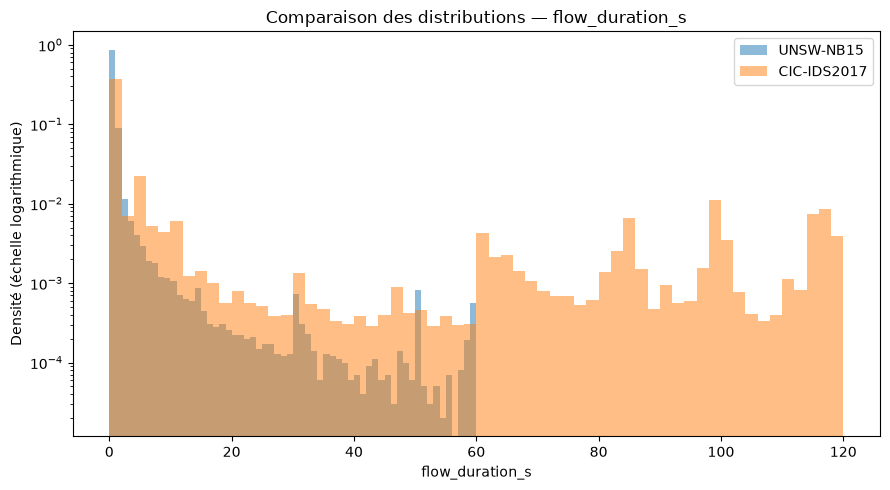

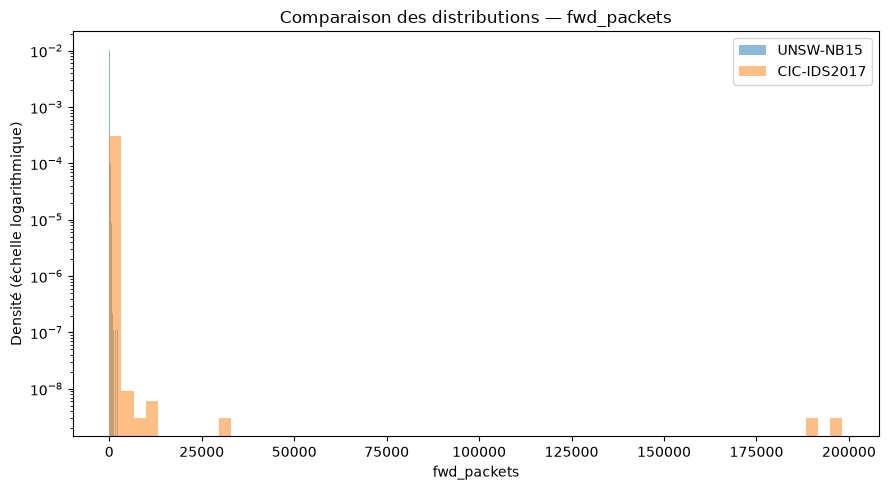

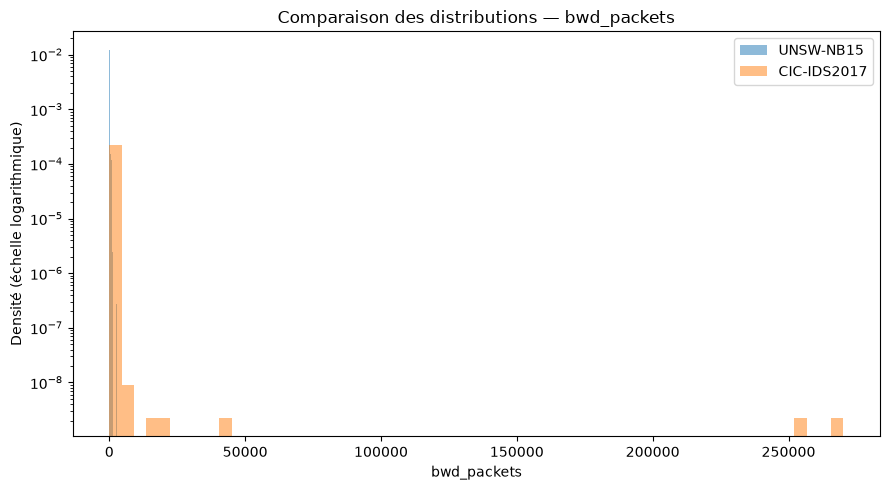

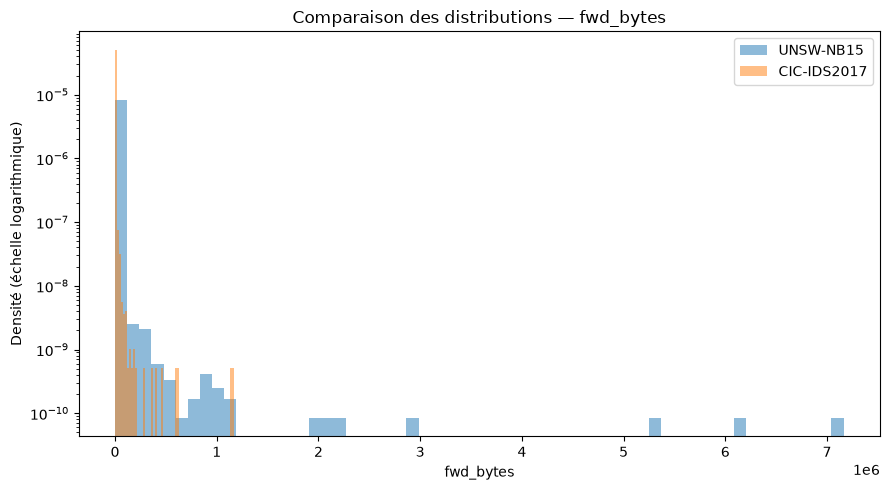

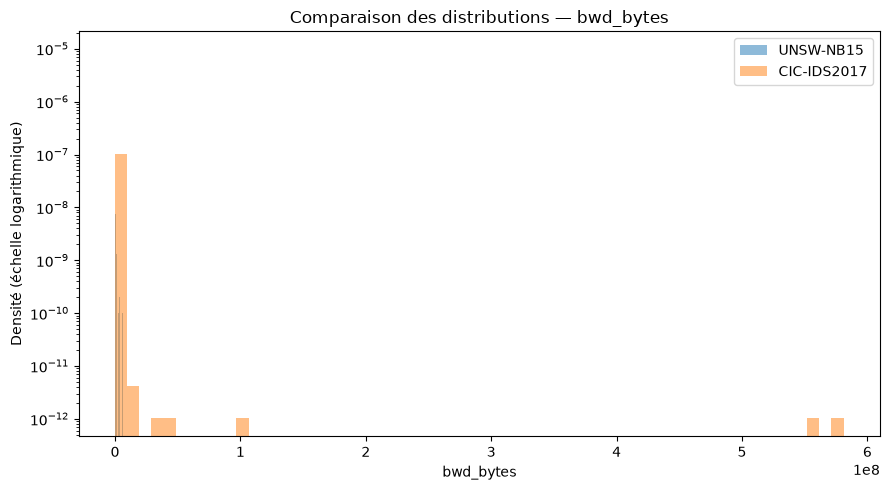

In [13]:
for feature in FEATURE_COLUMNS:
    plt.figure(figsize=(9, 5))
    plt.hist(X_unsw[feature], bins=60, alpha=0.5, density=True, label="UNSW-NB15")
    plt.hist(X_cic[feature], bins=60, alpha=0.5, density=True, label="CIC-IDS2017")
    plt.yscale("log")
    plt.title(f"Comparaison des distributions — {feature}")
    plt.xlabel(feature)
    plt.ylabel("Densité (échelle logarithmique)")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 14. Audit des doublons et conflits de labels

Les doublons sont évalués sur les cinq variables harmonisées. Des vecteurs identiques peuvent apparaître naturellement, et les conflits de labels doivent être signalés plutôt que supprimés automatiquement.

In [14]:
def duplicate_audit(X, y, dataset_name):
    frame = X.copy()
    frame["target"] = y.to_numpy()

    exact_duplicates = frame.duplicated(subset=FEATURE_COLUMNS + ["target"]).sum()
    feature_duplicates = X.duplicated(subset=FEATURE_COLUMNS).sum()
    conflicting_patterns = (
        frame.groupby(FEATURE_COLUMNS, dropna=False)["target"].nunique().gt(1).sum()
    )

    return {
        "dataset": dataset_name,
        "total_rows": len(frame),
        "exact_duplicate_rows": int(exact_duplicates),
        "feature_duplicate_rows": int(feature_duplicates),
        "feature_patterns_with_label_conflicts": int(conflicting_patterns),
    }

duplicate_results = pd.DataFrame([
    duplicate_audit(X_unsw, y_unsw, "UNSW-NB15"),
    duplicate_audit(X_cic, y_cic, "CIC-IDS2017"),
])
display(duplicate_results)
duplicate_results.to_csv(RESULTS_DIR / "harmonized_samples_duplicate_audit_v2.csv", index=False, encoding="utf-8-sig")

,dataset,total_rows,exact_duplicate_rows,feature_duplicate_rows,feature_patterns_with_label_conflicts
0,UNSW-NB15,100000,35833,35883,50
1,CIC-IDS2017,100000,25491,25706,215


## 15. Groupes de vecteurs identiques et validation sans chevauchement

Tous les enregistrements possédant exactement les mêmes cinq valeurs sont affectés au même groupe. `StratifiedGroupKFold` évite ainsi qu'un même vecteur de caractéristiques soit présent simultanément dans train et test.

In [15]:
from sklearn.model_selection import StratifiedGroupKFold

def create_feature_groups(X):
    groups, _ = pd.factorize(pd.MultiIndex.from_frame(X[FEATURE_COLUMNS]))
    return groups

def evaluate_group_splits(X, y, groups, dataset_name):
    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    rows = []
    split_indices = []

    for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y, groups), start=1):
        overlap = set(groups[train_idx]).intersection(set(groups[test_idx]))
        rows.append({
            "dataset": dataset_name,
            "fold": fold,
            "train_size": len(train_idx),
            "test_size": len(test_idx),
            "train_attack_pct": round(float(y.iloc[train_idx].mean() * 100), 2),
            "test_attack_pct": round(float(y.iloc[test_idx].mean() * 100), 2),
            "overlapping_groups": len(overlap),
        })
        split_indices.append((train_idx, test_idx))

    return pd.DataFrame(rows), split_indices

groups_unsw = create_feature_groups(X_unsw)
groups_cic = create_feature_groups(X_cic)

unsw_group_splits, unsw_split_indices = evaluate_group_splits(
    X_unsw, y_unsw, groups_unsw, "UNSW-NB15"
)
cic_group_splits, cic_split_indices = evaluate_group_splits(
    X_cic, y_cic, groups_cic, "CIC-IDS2017"
)

display(unsw_group_splits)
display(cic_group_splits)

assert (unsw_group_splits["overlapping_groups"] == 0).all()
assert (cic_group_splits["overlapping_groups"] == 0).all()
print("Aucun groupe de vecteurs identiques partagé entre train et test.")

,dataset,fold,train_size,test_size,train_attack_pct,test_attack_pct,overlapping_groups
0,UNSW-NB15,1,80004,19996,12.58,12.57,0
1,UNSW-NB15,2,79997,20003,12.58,12.58,0
2,UNSW-NB15,3,80003,19997,12.58,12.57,0
3,UNSW-NB15,4,79991,20009,12.57,12.59,0
4,UNSW-NB15,5,80005,19995,12.58,12.57,0


,dataset,fold,train_size,test_size,train_attack_pct,test_attack_pct,overlapping_groups
0,CIC-IDS2017,1,79999,20001,19.79,19.79,0
1,CIC-IDS2017,2,80001,19999,19.79,19.79,0
2,CIC-IDS2017,3,80001,19999,19.79,19.79,0
3,CIC-IDS2017,4,80001,19999,19.79,19.79,0
4,CIC-IDS2017,5,79998,20002,19.79,19.79,0


Aucun groupe de vecteurs identiques partagé entre train et test.


## 16. Sauvegarde des résultats et bilan

Les fichiers sont enregistrés avec le suffixe `_v2` pour ne pas écraser les audits précédents. Les séparations `.npz` existantes ne sont volontairement pas remplacées : leur correspondance avec l'ordre des lignes doit être vérifiée avant toute mise à jour.

In [16]:
unsw_group_splits.to_csv(
    RESULTS_DIR / "unsw_group_splits_audit_v2.csv",
    index=False,
    encoding="utf-8-sig",
)
cic_group_splits.to_csv(
    RESULTS_DIR / "cic_group_splits_audit_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Résultats enregistrés dans :", RESULTS_DIR)
print("\nBilan :")
print(f"- UNSW : {len(X_unsw):,} observations")
print(f"- CIC  : {len(X_cic):,} observations")
print(f"- Variables communes : {len(FEATURE_COLUMNS)}")
print(f"- Durées CIC négatives auditées : {negative_duration_count}")
print("- Fichiers .npz préexistants : non modifiés")

Résultats enregistrés dans : D:\Master-SDIA\CYB-1-IDS-Generalization\results\tables

Bilan :
- UNSW : 100,000 observations
- CIC  : 100,000 observations
- Variables communes : 5
- Durées CIC négatives auditées : 5
- Fichiers .npz préexistants : non modifiés
